In [ ]:
print("Sentiment Analysis Project Started")

import sys
print(sys.version)

Sentiment Analysis Project Started
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn transformers datasets

In [ ]:

from datasets import load_dataset
import pandas as pd

print("Loading Amazon Product Reviews Dataset...")

train_data = load_dataset(
    "fancyzhx/amazon_polarity",
    split="train",
    streaming=True
)

test_data = load_dataset(
    "fancyzhx/amazon_polarity",
    split="test",
    streaming=True
)

print("Dataset loaded successfully!")


Loading Amazon Product Reviews Dataset...


README.md:   0%|          | 0.00/6.81k [00:00<?, ?B/s]

Dataset loaded successfully!


In [ ]:

train_df = pd.DataFrame(
    list(train_data.shuffle(
        seed=42,
        buffer_size=10000
    ).take(5000))
)

test_df = pd.DataFrame(
    list(test_data.shuffle(
        seed=42,
        buffer_size=5000
    ).take(1000))
)

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))


Training samples: 5000
Testing samples: 1000


In [ ]:

print("First 5 Product Reviews:")

display(train_df.head())



First 5 Product Reviews:


,label,title,content
0,0,Not compatible with Flight Simulator X,The sound card was not compatible with Flight ...
1,1,Teen non-fiction,"Very nicely written and presented, the heartwa..."
2,0,Made in china,Don''t buy it. My dog loves the treat. HOWEVER...
3,1,Goldberg nails them.,This book does a great job of citing the peopl...
4,0,It reminded me of a novel,It reminded me of a novel in that it has no ta...


In [ ]:

train_df["sentiment"] = train_df["label"].map({
    0: "Negative",
    1: "Positive"
})

test_df["sentiment"] = test_df["label"].map({
    0: "Negative",
    1: "Positive"
})

display(train_df[["title", "sentiment"]].head(10))


,title,sentiment
0,Not compatible with Flight Simulator X,Negative
1,Teen non-fiction,Positive
2,Made in china,Negative
3,Goldberg nails them.,Positive
4,It reminded me of a novel,Negative
5,awesome,Positive
6,bimodal distributions are a bad sign,Negative
7,Lindsey Buckingham - Creative Genius,Positive
8,Wonderful book for both mathematical and non-m...,Positive
9,Worst CD of the century!!!,Negative


In [ ]:

train_df["review"] = (
    train_df["title"].fillna("") + " " +
    train_df["content"].fillna("")
)

test_df["review"] = (
    test_df["title"].fillna("") + " " +
    test_df["content"].fillna("")
)

print(train_df[["review", "sentiment"]].head())



                                              review sentiment
0  Not compatible with Flight Simulator X The sou...  Negative
1  Teen non-fiction Very nicely written and prese...  Positive
2  Made in china Don''t buy it. My dog loves the ...  Negative
3  Goldberg nails them. This book does a great jo...  Positive
4  It reminded me of a novel It reminded me of a ...  Negative


In [ ]:

train_df.to_csv("train_reviews.csv", index=False)
test_df.to_csv("test_reviews.csv", index=False)

print("Dataset saved successfully!")



Dataset saved successfully!


In [ ]:

print("Missing Values in Training Dataset:")

print(train_df.isnull().sum())

print("\nMissing Values in Testing Dataset:")

print(test_df.isnull().sum())


Missing Values in Training Dataset:
label        0
title        0
content      0
sentiment    0
review       0
dtype: int64

Missing Values in Testing Dataset:
label        0
title        0
content      0
sentiment    0
review       0
dtype: int64


In [ ]:

train_df = train_df.dropna(
    subset=["review", "sentiment"]
).copy()

test_df = test_df.dropna(
    subset=["review", "sentiment"]
).copy()

print("Missing values removed!")
print("Training data:", len(train_df))
print("Testing data:", len(test_df))


Missing values removed!
Training data: 5000
Testing data: 1000


In [ ]:

train_df = train_df.drop_duplicates(
    subset=["review"]
).copy()

test_df = test_df.drop_duplicates(
    subset=["review"]
).copy()

print("Duplicate reviews removed!")

print("Training records:", len(train_df))
print("Testing records:", len(test_df))


Duplicate reviews removed!
Training records: 5000
Testing records: 1000


In [ ]:

import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

train_df["cleaned_review"] = train_df["review"].apply(clean_text)

test_df["cleaned_review"] = test_df["review"].apply(clean_text)

print("Text cleaning completed!")

print(train_df[["review", "cleaned_review"]].head())


Text cleaning completed!
                                              review  \
0  Not compatible with Flight Simulator X The sou...   
1  Teen non-fiction Very nicely written and prese...   
2  Made in china Don''t buy it. My dog loves the ...   
3  Goldberg nails them. This book does a great jo...   
4  It reminded me of a novel It reminded me of a ...   

                                      cleaned_review  
0  not compatible with flight simulator x the sou...  
1  teen nonfiction very nicely written and presen...  
2  made in china dont buy it my dog loves the tre...  
3  goldberg nails them this book does a great job...  
4  it reminded me of a novel it reminded me of a ...  


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train = tfidf.fit_transform(
    train_df["cleaned_review"]
)

X_test = tfidf.transform(
    test_df["cleaned_review"]
)

print("TF-IDF conversion completed!")

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


TF-IDF conversion completed!
Training shape: (5000, 5000)
Testing shape: (1000, 5000)


In [ ]:

y_train = train_df["label"]
y_test = test_df["label"]

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nPreprocessing Completed Successfully!")


Training labels: (5000,)
Testing labels: (1000,)

Preprocessing Completed Successfully!


In [ ]:

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

print("Machine Learning libraries imported successfully!")


Machine Learning libraries imported successfully!


In [ ]:

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Logistic Regression Model Created!")


Logistic Regression Model Created!


In [ ]:

print("Training Started...")

model.fit(X_train, y_train)

print("Model Training Completed Successfully!")


Training Started...
Model Training Completed Successfully!


In [ ]:

y_pred = model.predict(X_test)

print("Prediction Completed!")

print("First 10 Actual Labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Labels:")
print(y_pred[:10])


Prediction Completed!
First 10 Actual Labels:
[1 0 0 1 1 1 1 1 0 1]

First 10 Predicted Labels:
[1 0 0 1 1 1 1 1 0 1]


In [ ]:

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)


Model Accuracy: 82.5 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.85      0.78      0.81       491
    Positive       0.81      0.86      0.83       509

    accuracy                           0.82      1000
   macro avg       0.83      0.82      0.82      1000
weighted avg       0.83      0.82      0.82      1000



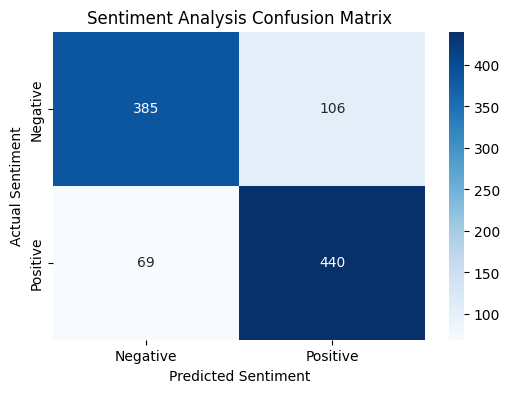

In [ ]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Sentiment Analysis Confusion Matrix")

plt.show()


In [ ]:

def predict_sentiment(review):

    cleaned = clean_text(review)

    review_vector = tfidf.transform([cleaned])

    prediction = model.predict(review_vector)[0]

    if prediction == 1:
        return "Positive"
    else:
        return "Negative"


print("Prediction function created!")


Prediction function created!


In [ ]:

review1 = "This product is amazing and the quality is excellent"

review2 = "Very poor quality and completely disappointed"

print("Review 1:", predict_sentiment(review1))

print("Review 2:", predict_sentiment(review2))


Review 1: Positive
Review 2: Negative


In [ ]:

user_review = input("Enter your product review: ")

result = predict_sentiment(user_review)

print("\nPredicted Sentiment:", result)


Enter your product review: This product is amazing and quality is very good

Predicted Sentiment: Positive


In [ ]:

import joblib

joblib.dump(model, "sentiment_model.pkl")

joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and Vectorizer Saved Successfully!")


Model and Vectorizer Saved Successfully!


In [ ]:

!pip install transformers torch


In [ ]:

from transformers import pipeline

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english"
)

print("Hugging Face Model Loaded Successfully!")


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Hugging Face Model Loaded Successfully!


In [ ]:

review = "This product is amazing and I love it"

result = sentiment_pipeline(review)

print("Review:", review)
print("Hugging Face Prediction:", result)


Review: This product is amazing and I love it
Hugging Face Prediction: [{'label': 'POSITIVE', 'score': 0.9998887777328491}]


In [ ]:

sample_reviews = [
    "This product is excellent and very useful",
    "Worst product. I am not happy",
    "Good quality and fast delivery",
    "The product stopped working after one day",
    "I really love this purchase"
]

for review in sample_reviews:

    ml_result = predict_sentiment(review)

    ai_result = sentiment_pipeline(review)[0]["label"]

    print("\nReview:", review)
    print("Our ML Model:", ml_result)
    print("Hugging Face Model:", ai_result)



Review: This product is excellent and very useful
Our ML Model: Positive
Hugging Face Model: POSITIVE

Review: Worst product. I am not happy
Our ML Model: Negative
Hugging Face Model: NEGATIVE

Review: Good quality and fast delivery
Our ML Model: Positive
Hugging Face Model: POSITIVE

Review: The product stopped working after one day
Our ML Model: Negative
Hugging Face Model: NEGATIVE

Review: I really love this purchase
Our ML Model: Positive
Hugging Face Model: POSITIVE


In [ ]:

from sklearn.metrics import accuracy_score

sample_test = test_df.sample(
    n=min(100, len(test_df)),
    random_state=42
)

hf_predictions = []

reviews = sample_test["review"].tolist()

for i in range(0, len(reviews), 16):

    batch = reviews[i:i+16]

    results = sentiment_pipeline(
        batch,
        truncation=True
    )

    hf_predictions.extend([
        1 if item["label"] == "POSITIVE" else 0
        for item in results
    ])

hf_accuracy = accuracy_score(
    sample_test["label"],
    hf_predictions
)

print("Hugging Face Accuracy:",
      round(hf_accuracy * 100, 2), "%")


Hugging Face Accuracy: 89.0 %


,Model,Accuracy
0,Logistic Regression,87.0
1,Hugging Face DistilBERT,89.0


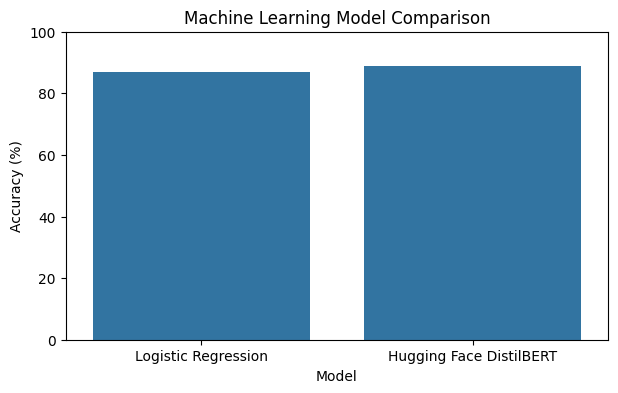

In [ ]:

lr_predictions = model.predict(
    tfidf.transform(sample_test["cleaned_review"])
)

lr_accuracy = accuracy_score(
    sample_test["label"],
    lr_predictions
)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Hugging Face DistilBERT"],
    "Accuracy": [
        lr_accuracy * 100,
        hf_accuracy * 100
    ]
})

display(comparison)

plt.figure(figsize=(7, 4))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()


In [ ]:

test_results = test_df.copy()

test_results["predicted"] = y_pred

errors = test_results[
    test_results["label"] != test_results["predicted"]
]

print("Total Wrong Predictions:", len(errors))

display(
    errors[["review", "sentiment", "predicted"]].head(10)
)


Total Wrong Predictions: 175


,review,sentiment,predicted
21,Only one problem with the backgammon set I pur...,Positive,0
22,Make sure you see Jean de Florette first This ...,Positive,0
32,It would be great if it stayed inflated! I hav...,Negative,1
33,Solitary Witch I bought this book a few years ...,Positive,0
46,Dude!!! Sweet!!! This movie is SOOO funny!!! I...,Positive,0
47,Beginning of the end of American leadership in...,Negative,1
48,"Remember children, it's only the concepts. Cal...",Positive,0
49,Book Critic2 I was a little dissapointed with ...,Negative,1
53,"a story hidden in words Way too many names, Wa...",Negative,1
56,Good ink I bought this to replace my Omas blac...,Positive,0


In [ ]:

errors.to_csv("error_analysis.csv", index=False)

print("Error Analysis Saved Successfully!")


Error Analysis Saved Successfully!


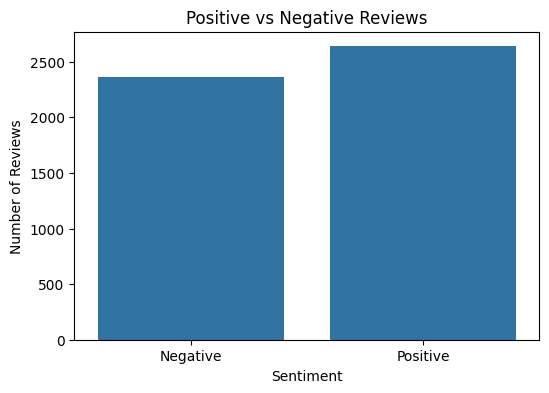

In [ ]:

plt.figure(figsize=(6, 4))

sns.countplot(
    data=train_df,
    x="sentiment"
)

plt.title("Positive vs Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()


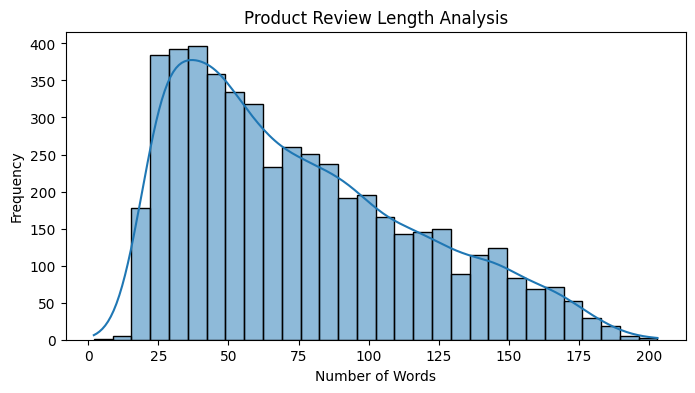

In [ ]:

train_df["review_length"] = train_df["cleaned_review"].apply(
    lambda x: len(x.split())
)

plt.figure(figsize=(8, 4))

sns.histplot(
    train_df["review_length"],
    bins=30,
    kde=True
)

plt.title("Product Review Length Analysis")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()


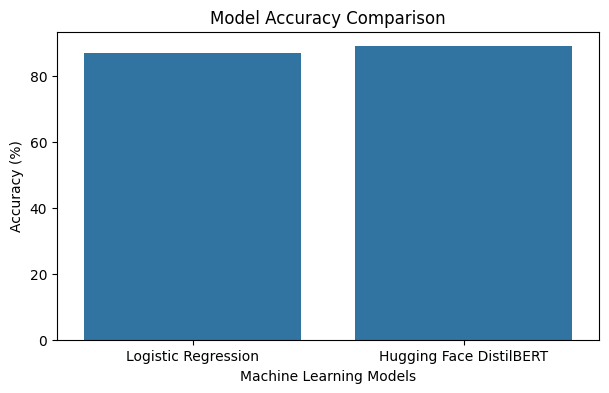

In [ ]:

plt.figure(figsize=(7, 4))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.show()


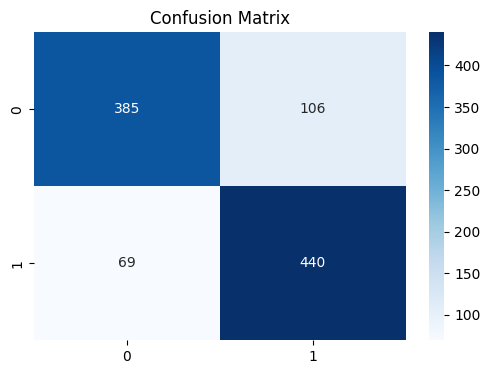

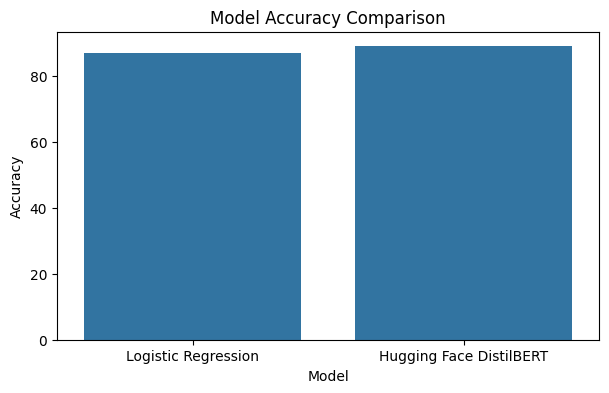

All graphs saved successfully!


In [ ]:

import os

os.makedirs("results", exist_ok=True)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.savefig("results/confusion_matrix.png")

plt.show()

plt.figure(figsize=(7, 4))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.savefig("results/model_comparison.png")

plt.show()

print("All graphs saved successfully!")


In [ ]:

os.makedirs("dataset", exist_ok=True)

train_df.to_csv(
    "dataset/train_reviews.csv",
    index=False
)

test_df.to_csv(
    "dataset/test_reviews.csv",
    index=False
)

print("Datasets saved successfully!")


Datasets saved successfully!


In [ ]:

import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(
    model,
    "models/sentiment_model.pkl"
)

joblib.dump(
    tfidf,
    "models/tfidf_vectorizer.pkl"
)

print("Machine Learning models saved!")


Machine Learning models saved!


In [ ]:

errors.to_csv(
    "results/error_analysis.csv",
    index=False
)

print("Error analysis saved!")


Error analysis saved!


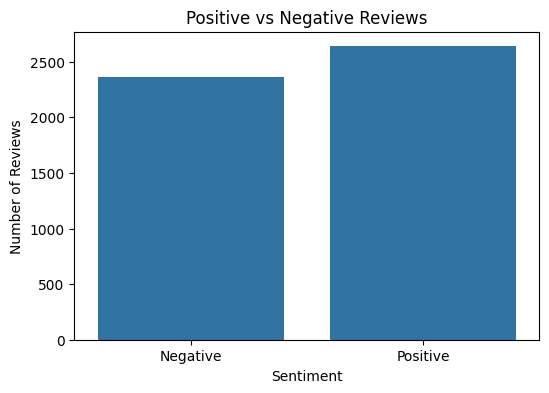

In [ ]:

plt.figure(figsize=(6, 4))

sns.countplot(data=train_df, x="sentiment")

plt.title("Positive vs Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()


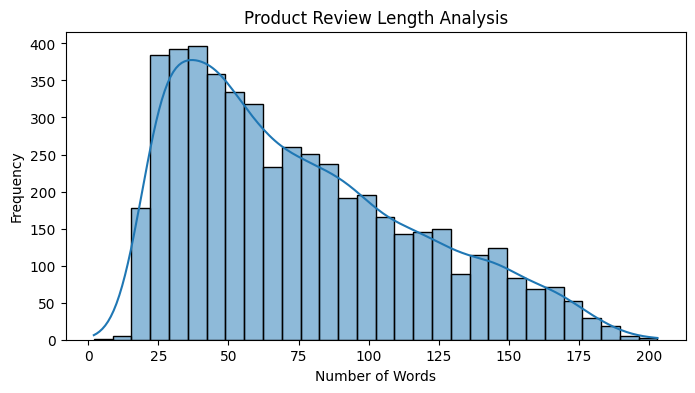

In [ ]:

train_df["review_length"] = train_df["cleaned_review"].apply(
    lambda x: len(x.split())
)

plt.figure(figsize=(8, 4))

sns.histplot(train_df["review_length"], bins=30, kde=True)

plt.title("Product Review Length Analysis")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()


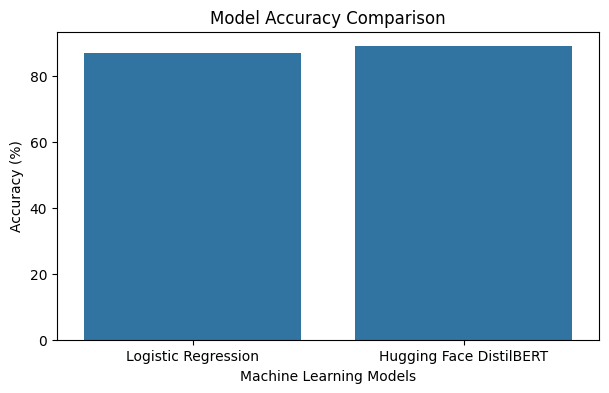

In [ ]:

plt.figure(figsize=(7, 4))

sns.barplot(data=comparison, x="Model", y="Accuracy")

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.show()


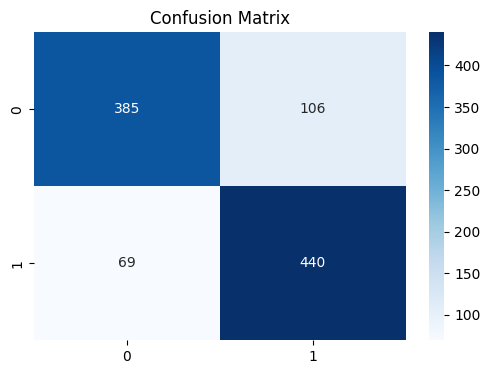

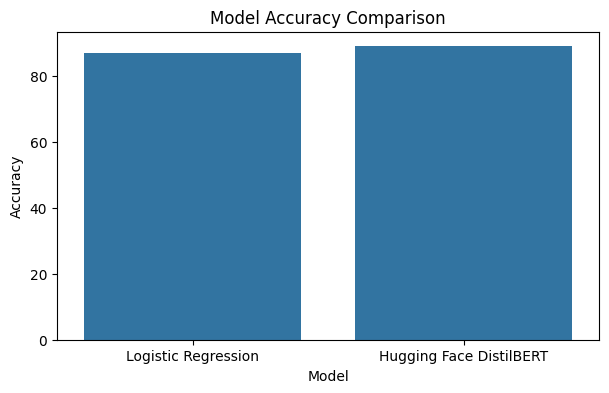

All graphs saved successfully!


In [ ]:

import os

os.makedirs("results", exist_ok=True)

# Save confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.savefig("results/confusion_matrix.png")
plt.show()

# Save model comparison
plt.figure(figsize=(7, 4))

sns.barplot(data=comparison, x="Model", y="Accuracy")

plt.title("Model Accuracy Comparison")
plt.savefig("results/model_comparison.png")
plt.show()

print("All graphs saved successfully!")


In [ ]:

os.makedirs("dataset", exist_ok=True)

train_df.to_csv(
    "dataset/train_reviews.csv",
    index=False
)

test_df.to_csv(
    "dataset/test_reviews.csv",
    index=False
)

print("Datasets saved successfully!")


Datasets saved successfully!


In [ ]:

import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(model, "models/sentiment_model.pkl")

joblib.dump(tfidf, "models/tfidf_vectorizer.pkl")

print("Models saved successfully!")


Models saved successfully!


In [ ]:

os.makedirs("results", exist_ok=True)

errors.to_csv(
    "results/error_analysis.csv",
    index=False
)

print("Error analysis saved successfully!")


Error analysis saved successfully!


In [ ]:

requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
transformers
datasets
torch
joblib
"""

with open("requirements.txt", "w") as file:
    file.write(requirements.strip())

print("Requirements file created successfully!")


Requirements file created successfully!


In [ ]:

import os

for folder, subfolders, files in os.walk("."):
    if any(skip in folder for skip in [
        "./.config", "./.ipython", "./.cache"
    ]):
        continue

    for filename in files:
        print(os.path.join(folder, filename))


./train_reviews.csv
./requirements.txt
./tfidf_vectorizer.pkl
./sentiment_model.pkl
./error_analysis.csv
./test_reviews.csv
./models/tfidf_vectorizer.pkl
./models/sentiment_model.pkl
./dataset/train_reviews.csv
./dataset/test_reviews.csv
./results/confusion_matrix.png
./results/model_comparison.png
./results/error_analysis.csv
./sample_data/README.md
./sample_data/anscombe.json
./sample_data/california_housing_test.csv
./sample_data/california_housing_train.csv
./sample_data/mnist_test.csv
./sample_data/mnist_train_small.csv


In [ ]:

import shutil

shutil.make_archive(
    "Sentiment_Analysis_Project",
    "zip",
    ".",
    base_dir="."
)

print("Project ZIP created successfully!")


RuntimeError: File size too large, try using force_zip64

In [ ]:
import shutil
import os

shutil.make_archive(
    "/content/Sentiment_Analysis_Project",
    "zip",
    "/content",
    "dataset"
)

print("ZIP created successfully!")

ZIP created successfully!
